## Non-Renewals by Fire Hazard Tier
Join each ZIP code's fire hazard share to its non-renewal data, group ZIPs into hazard tiers, and compare non-renewal rates by tier from 2015 to 2023

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

clean = Path("../data/clean")

cdi = pd.read_csv(clean / "cdi_nonrenewals_by_zip_year.csv", dtype = {"zip": str})
share = pd.read_csv(clean / "zip_fire_hazard_share.csv", dtype = {"zip": str})
print(cdi.shape, share.shape)

(23545, 11) (1802, 4)


In [2]:
#join them
#how = "inner" keeps only ZIP codes that appear on both tables, dropping those without a shape
df = cdi.merge(share, on = "zip", how = "inner")

kept = df["up_for_renewal"].sum() / cdi["up_for_renewal"].sum()
print(df.shape)
print(f"Policies kept: {kept:.2%}")

(19503, 14)
Policies kept: 99.97%


In [3]:
#choose hazard tiers so we rely on the data, not our estimates
#first line shows us the share of ZIP codes with no high-hazard land
zip_shares = df.drop_duplicates("zip")["share_high_or_vh"]
print((zip_shares == 0).mean())
zip_shares.quantile([0.25, 0.5, 0.75, 0.9])

0.3331479421579533


0.25    0.000000
0.50    0.158407
0.75    0.587673
0.90    0.851188
Name: share_high_or_vh, dtype: float64

In [4]:
#assign tiers and check their sizes
#pd.cut sorts each ZIP into a tier based on share
#right = False includes edges
#printout shows how many ZIP codes and what share of policies fall in each tier (no ZIP is left without a tier)
df["tier"] = pd.cut(
    df["share_high_or_vh"],
    bins = [0, 0.10, 0.50, 1.0001],
    right = False,
    labels = ["Low (<10%)", "Moderate (10-50%)", "High (50%+)"],
)

tier_sizes = df.drop_duplicates("zip").groupby("tier", observed = True).size()
tier_policies = df.groupby("tier", observed = True)["up_for_renewal"].sum()
print(tier_sizes)
print((tier_policies / tier_policies.sum()).round(3))

tier
Low (<10%)           827
Moderate (10-50%)    426
High (50%+)          545
dtype: int64
tier
Low (<10%)           0.495
Moderate (10-50%)    0.253
High (50%+)          0.253
Name: up_for_renewal, dtype: float64


In [5]:
#share of policies up for renewal in each tier, main file only (avoids double-counting 2020-21)
main_rows = df[df["source"] == "2015-2021 file"]
tier_share = main_rows.groupby("tier", observed = True)["up_for_renewal"].sum()
(tier_share / tier_share.sum() * 100).round(1)

tier
Low (<10%)           49.2
Moderate (10-50%)    25.3
High (50%+)          25.5
Name: up_for_renewal, dtype: float64

In [6]:
#sum rates by source file, tier, and year
#adds the counts up within each group first, then divides; so a big ZIP code counts more than a smaller one
#we do this to make sure the proportion to its policies is fair
#min_count = 1 keeps missing data as blank, not 0
rates = (
    df.groupby(["source", "tier", "year"], observed = True)
      [["nonrenewed", "nonrenewed_insurer", "up_for_renewal"]]
      .sum(min_count = 1)
      .reset_index()
)
rates["nonrenewal_rate"] = rates["nonrenewed"] / rates["up_for_renewal"]
rates["insurer_rate"] = rates["nonrenewed_insurer"] / rates["up_for_renewal"]

In [7]:
#check numbers before plotting the insurer-initiated rate and the total rate by tier, 2015-2021
main = rates[rates["source"] == "2015-2021 file"]
print(main.pivot(index = "year", columns = "tier", values = "insurer_rate").round(3))
print(main.pivot(index = "year", columns = "tier", values = "nonrenewal_rate").round(3))

tier  Low (<10%)  Moderate (10-50%)  High (50%+)
year                                            
2015       0.022              0.021        0.023
2016       0.021              0.021        0.022
2017       0.020              0.019        0.020
2018       0.019              0.020        0.021
2019       0.019              0.030        0.041
2020       0.017              0.022        0.030
2021       0.023              0.029        0.036
tier  Low (<10%)  Moderate (10-50%)  High (50%+)
year                                            
2015       0.108              0.109        0.108
2016       0.108              0.110        0.110
2017       0.109              0.109        0.109
2018       0.106              0.109        0.110
2019       0.110              0.123        0.135
2020       0.107              0.118        0.128
2021       0.121              0.130        0.140


In [8]:
#insurer-initiated rate by tier, before vs. after the 2017-18 fire seasons
before_after = main.assign(period = main["year"].map(lambda y: "2015-2018" if y <= 2018 else "2019-2021"))
before_after = before_after.groupby(["tier", "period"], observed = True)[["nonrenewed_insurer", "up_for_renewal"]].sum()
before_after["insurer_rate"] = before_after["nonrenewed_insurer"] / before_after["up_for_renewal"]

#round the rates first, then subtract, so the change matches the rounded rates in the README
table = (before_after["insurer_rate"].unstack("period") * 100).round(2)
table["change (pts)"] = (table["2019-2021"] - table["2015-2018"]).round(2)
table

period,2015-2018,2019-2021,change (pts)
tier,,,
Low (<10%),2.01,1.96,-0.05
Moderate (10-50%),2.04,2.69,0.65
High (50%+),2.16,3.58,1.42


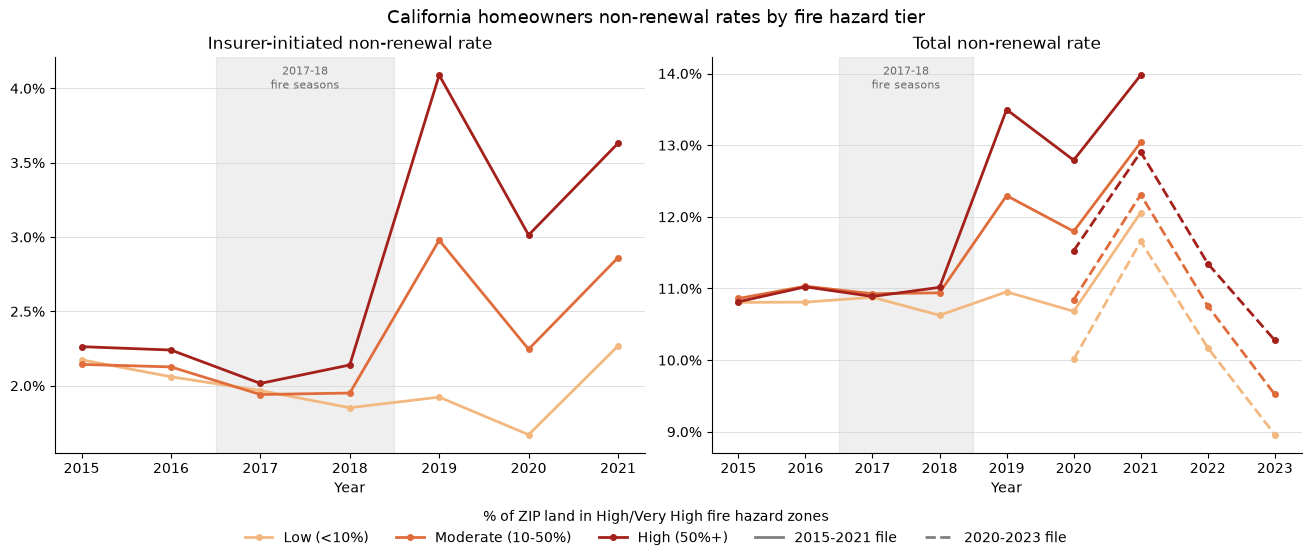

In [9]:
#the big plot
from matplotlib.ticker import PercentFormatter
from matplotlib.lines import Line2D

colors = {"Low (<10%)": "#f2b880", "Moderate (10-50%)": "#e06c3c", "High (50%+)": "#a3201b"}
fig, axes = plt.subplots(1, 2, figsize = (13, 5.5), layout = "constrained")

for tier, color in colors.items():
    old_t = rates[(rates["source"] == "2015-2021 file") & (rates["tier"] == tier)]
    new_t = rates[(rates["source"] == "2020-2023 file") & (rates["tier"] == tier)]

    axes[0].plot(old_t["year"], old_t["insurer_rate"], color = color, marker = "o", markersize = 4, linewidth = 2)
    axes[1].plot(old_t["year"], old_t["nonrenewal_rate"], color = color, marker = "o", markersize = 4, linewidth = 2)
    axes[1].plot(new_t["year"], new_t["nonrenewal_rate"], color = color, marker = "o", markersize = 4,
                 linewidth = 2, linestyle = "--")

axes[0].set_title("Insurer-initiated non-renewal rate")
axes[1].set_title("Total non-renewal rate")

for ax in axes:
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals = 1))
    ax.set_xlabel("Year")
    ax.grid(axis = "y", color = "lightgrey", linewidth = 0.5)
    ax.spines[["top", "right"]].set_visible(False)
    ax.axvspan(2016.5, 2018.5, color = "grey", alpha = 0.12)
    ax.text(2017.5, 0.98, "2017-18\nfire seasons", transform = ax.get_xaxis_transform(),
            ha = "center", va = "top", fontsize = 8, color = "dimgrey")

#legend: tier colors plus a solid/dashed key for the two CDI files
handles = [Line2D([], [], color = c, linewidth = 2, marker = "o", markersize = 4, label = t) for t, c in colors.items()]
handles += [Line2D([], [], color = "grey", linewidth = 2, label = "2015-2021 file"),
            Line2D([], [], color = "grey", linewidth = 2, linestyle = "--", label = "2020-2023 file")]
fig.legend(handles = handles, title = "% of ZIP land in High/Very High fire hazard zones",
           loc = "outside lower center", ncol = 5, frameon = False)

fig.suptitle("California homeowners non-renewal rates by fire hazard tier", fontsize = 13)
plt.savefig("../images/nonrenewal_by_tier.png", dpi = 150, bbox_inches = "tight")

In [10]:
#save
rates.to_csv(clean / "nonrenewal_rates_by_tier.csv", index = False)

About 25% of homeowners policies up for renewal from 2015 to 2021 were in ZIP codes where at least half the land is High or Very High fire hazard. From 2015 to 2018, every tier had about the same insurer-initiated non-renewal rate (around 2%). After the 2017 and 2018 fire seasons, the gap opened: in 2019, High-tier ZIP codes were dropped at 4.1%, around twice the Low tier's 1.9%, with Moderate in between. High stayed highest through 2023 in both files, though the tiers use the 2025 hazard maps applied back to 2015.